# **Drilling Analysis**
## Drilling by operator

This notebook contains code to generate a chart showing **monthly drilling by operator.**

**First,** import drilling data

In [2]:
# Import libraries
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib import lines

In [ ]:
# Load data
PATH = os.path.join('..', '..', 'data', 'oil_intermediate')
df_op = pd.read_csv(PATH + '/02_drill_op.csv')

**Second,** aggregate by location

In [21]:
# Group by and aggregate for land and offshore
df_agg = (
    df_op.query('ubicacion == "Terrestre"')
    .groupby(['ubicacion', 'fecha'], as_index=False)
    .agg(n_wells_land = ('pozos_perforados', 'sum'))[['fecha', 'n_wells_land']]
    .merge(
        df_op.query('ubicacion == "Maritima"')
        .groupby(['ubicacion', 'fecha'], as_index=False)
        .agg(n_wells_offshore = ('pozos_perforados', 'sum'))[['fecha', 'n_wells_offshore']],
        how='left',
        on='fecha'
    )
    .fillna(0)
)

**Third,** create a chart for the two aggregated series

In [66]:
# Year labels for x-axis labels
x_labels = []


for i in range(2002, 2020, 2):

    l = f'{i}'
    x_labels.append(l)

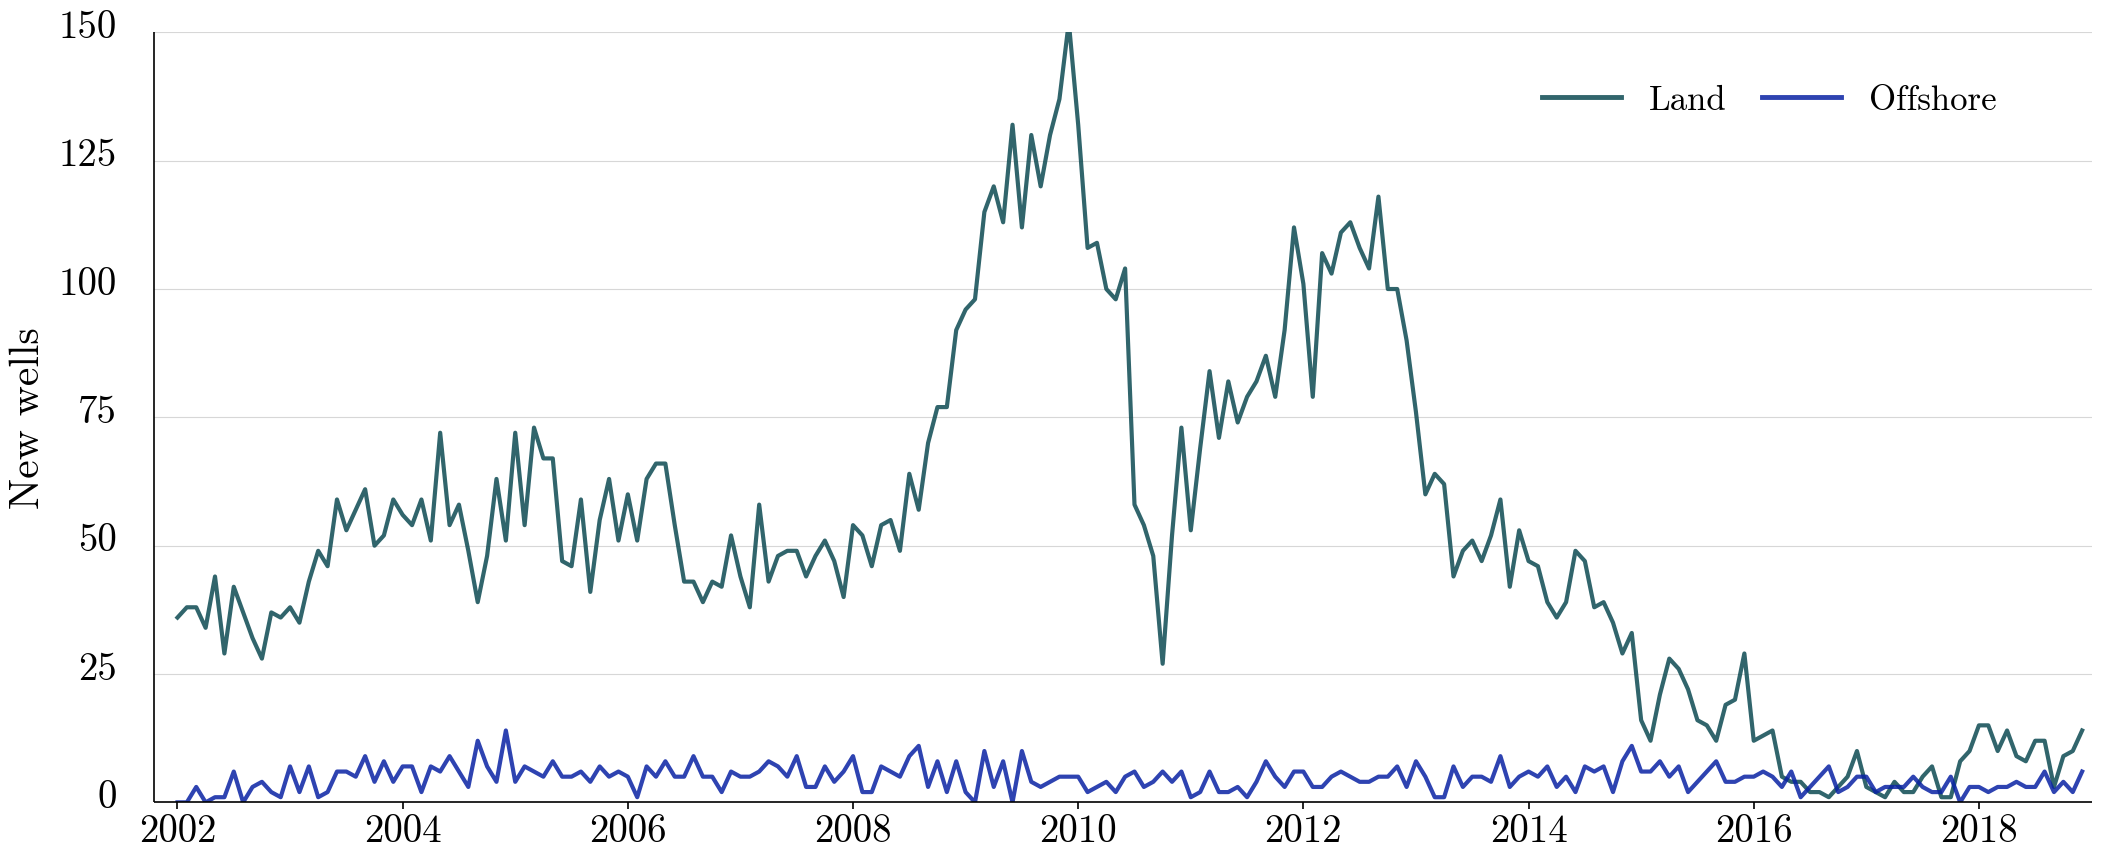

In [85]:
# Create subplots object
fig, ax = plt.subplots(figsize=(25,10))

# Y-axis settings
ax.set_ylim(0, 150)
ax.set_ylabel('New wells', fontsize=30, fontweight=100, fontfamily="cmr10") # <- Axis name label
ax.yaxis.set_label_coords(-0.055, 0.5)
ax.yaxis.set_tick_params(labelleft=False, length=0)
ax.yaxis.set_ticks(list(range(0, 151, 25)))

# Y-axis labels
for i in range(0,151,25):

    ax.text(
        -6.5, i-1, f'{i:,}', 
        ha="right", va="baseline", fontsize=28,
        fontfamily="cmr10", fontweight=100
    )

# X-axis settings
ax.set_xlim(-2.5, 204)
ax.xaxis.set_ticks(list(range(0, 216, 24)))
ax.xaxis.set_ticklabels(x_labels, fontsize=28, fontweight=100, fontfamily="cmr10")
ax.xaxis.set_tick_params(length=5, width=1.2)

# Spine settings
ax.spines["bottom"].set_lw(1.2)
ax.spines["bottom"].set_capstyle("butt")
ax.spines['left'].set_lw(1.2)
ax.spines['left'].set_capstyle("butt")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Grid settings
ax.grid(axis='y', alpha=0.5)

# Series
ax.plot(df_agg['n_wells_land'].values, lw=3, color="#0D4A52", alpha=0.85)
ax.plot(df_agg['n_wells_offshore'].values, lw=3, color="#0922A4", alpha=0.85)

# Legend settings
legend_handles = [
    lines.Line2D([0], [0], color="#0D4A52", lw=3.5, alpha=0.85, label="Land"),
    lines.Line2D([0], [0], color="#0922A4", lw=3.5, alpha=0.85, label="Offshore")
]

ax.legend(
    handles=legend_handles,
    loc="lower left",
    bbox_to_anchor=(0.7, 0.85),
    bbox_transform=ax.transAxes,
    frameon=False,
    ncol=2,
    handlelength=2.3,
    columnspacing=1.0,
    prop={"family": "cmr10", "size": 25}
)

# Tight layout
#fig.tight_layout()

# Show plot
plt.show()

